# Análise de aluguel em São Paulo
##  Conhecendo os dados

In [1]:
import pandas as pd

df = pd.read_csv("data.csv")


In [2]:
df.head()

,address,district,area,bedrooms,garage,type,rent,total
0,Rua Herval,Belenzinho,21,1,0,Studio e kitnet,2400,2939
1,Avenida São Miguel,Vila Marieta,15,1,1,Studio e kitnet,1030,1345
2,Rua Oscar Freire,Pinheiros,18,1,0,Apartamento,4000,4661
3,Rua Júlio Sayago,Vila Ré,56,2,2,Casa em condomínio,1750,1954
4,Rua Barata Ribeiro,Bela Vista,19,1,0,Studio e kitnet,4000,4654


In [3]:
df.shape

(11657, 8)

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11657 entries, 0 to 11656
Data columns (total 8 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   address   11657 non-null  object
 1   district  11657 non-null  object
 2   area      11657 non-null  int64 
 3   bedrooms  11657 non-null  int64 
 4   garage    11657 non-null  int64 
 5   type      11657 non-null  object
 6   rent      11657 non-null  int64 
 7   total     11657 non-null  int64 
dtypes: int64(5), object(3)
memory usage: 728.7+ KB


In [5]:
df.describe()

,area,bedrooms,garage,rent,total
count,11657.000000,11657.000000,11657.000000,11657.000000,11657.000000
mean,84.655658,1.966286,1.060393,3250.814789,4080.030625
std,74.020536,0.931313,1.132349,2650.711557,3352.480274
min,0.000000,0.000000,0.000000,500.000000,509.000000
25%,40.000000,1.000000,0.000000,1590.000000,1996.000000
50%,60.000000,2.000000,1.000000,2415.000000,3057.000000
75%,96.000000,3.000000,2.000000,3800.000000,4774.000000
max,580.000000,6.000000,6.000000,25000.000000,28700.000000


| Coluna | O que representa |
|---|---|
| address | endereço (rua) do imóvel |
| district | bairro ou distrito onde o imóvel fica |
| area | área do imóvel em metros quadrados (m²) |
| bedrooms | número de quartos |
| garage | número de vagas de estacionamento |
| type | tipo do imóvel (apartamento, casa, studio e kitnet, casa em condomínio) |
| rent | aluguel mensal |
| total | custo total: aluguel mais impostos e outras taxas |

Descrições conferidas na página do dataset no Kaggle e reescritas por mim.

## Qualidade dos dados




In [6]:
print(df.isna().sum())
print(df.duplicated().sum())

address     0
district    0
area        0
bedrooms    0
garage      0
type        0
rent        0
total       0
dtype: int64
0


Imóveis com área igual a 0

In [7]:
area_zero = df[df["area"] == 0]
print(len(area_zero))
area_zero.head()

2


,address,district,area,bedrooms,garage,type,rent,total
2983,Rua Relíquia,Jardim das Laranjeiras,0,2,1,Apartamento,1600,2569
7085,Rua Edmundo de Amicis,Morumbi,0,3,2,Casa,3200,3351


Aqui encontrei 2 imóveis com área igual a 0, entre 11.657 registros (menos de 0,02%).
Decidi removê-los porque área 0 é impossível: ou os dados não foram preenchidos
direito ou estão errados. Como são poucos, remover não afeta a análise, e prefiro
isso a inventar um valor no lugar. Depois da limpeza, o df_limpo ficou com 11.655
linhas, e o df original continua guardado.

In [8]:
df_limpo = df[df["area"] != 0].copy()
df_limpo.shape

(11655, 8)

## Tipos de imóvel

In [9]:
df_limpo["type"].value_counts()

,count
type,
Apartamento,7193
Casa,2840
Studio e kitnet,1381
Casa em condomínio,241


In [10]:
df_limpo["type"].value_counts(normalize=True)

,proportion
type,
Apartamento,0.617160
Casa,0.243672
Studio e kitnet,0.118490
Casa em condomínio,0.020678


A coluna type tem 4 categorias: Apartamento, Casa, Studio e kitnet e Casa em
condomínio. Todas estão escritas de forma consistente, sem variações de grafia,
e a soma delas dá 11.655, o mesmo total do df_limpo. Por isso não precisei fazer
nenhuma limpeza nessa coluna. Os apartamentos são a maior parte dos anúncios
(cerca de 62%), seguidos por casas (24%), studios e kitnets (12%) e casas em
condomínio (2%). Isso significa que os resultados gerais refletem principalmente
apartamentos, e vou registrar isso como limitação.

## Bairros: grafias duplicadas

In [11]:
df_limpo["district"].value_counts()

,count
district,
Bela Vista,352
Vila Mariana,232
Jardim Paulista,220
Centro,178
Pinheiros,159
...,...
Nova Aldeinha,1
Pacaembu.,1
Parque Munhoz,1


In [12]:
pacaembu = df_limpo[df_limpo["district"].str.contains("Pacaembu")]
pacaembu["district"].value_counts()

,count
district,
Pacaembu,5
Pacaembu.,1


In [13]:
df_limpo["district"].str.strip().str.lower().nunique()

1181

In [14]:
df_limpo["district_norm"] = df_limpo["district"].str.strip().str.lower().str.rstrip(".")

In [15]:
df_limpo["district_norm"].nunique()

1178

A coluna district tinha 1.199 bairros diferentes. Olhando a tabela, vi que o
Pacaembu aparecia também com um ponto no final ("Pacaembu."), e o pandas tratava
isso como um bairro diferente. Para corrigir, criei a coluna district_norm, tirando
espaços sobrando, passando tudo para minúsculas e removendo o ponto final. Com isso,
o total caiu para 1.178 bairros, então o problema afetava mais nomes além do
Pacaembu. Mantive a coluna original e, nas análises por bairro, uso a district_norm.

In [16]:
df_limpo[df_limpo["district_norm"].str.contains("pacaembu")]["district_norm"].value_counts()

,count
district_norm,
pacaembu,6


## Conferindo a relação entre rent e total




In [17]:
total_menor = df_limpo[df_limpo["rent"] > df_limpo["total"]]
print(len(total_menor))

0


In [18]:
df_limpo["diferenca"] = df_limpo["total"] - df_limpo["rent"]
df_limpo["diferenca"].describe()


,diferenca
count,11655.000000
mean,829.262033
std,938.971426
min,9.000000
25%,268.000000
50%,577.000000
75%,1016.000000
max,13700.000000


Segundo a página do dataset no Kaggle, rent é o aluguel mensal do imóvel e total é
o custo total, incluindo aluguel, impostos e outras taxas. Para conferir isso nos
dados, procurei imóveis em que o aluguel fosse maior que o total e não encontrei
nenhum (0 linhas). Também criei a coluna diferenca (total menos rent), que não
existe no arquivo original. O menor valor dela é 9, a mediana é 577 e o maior é
13.700, ou seja, o total é sempre maior que o aluguel, e o valor extra varia bastante
de um imóvel para outro. Por isso não precisei fazer nenhuma limpeza nessa relação.

## Análise de preços
### Média e mediana do aluguel

In [19]:
df_limpo["rent"].mean()


np.float64(3250.9607893607895)

In [20]:

df_limpo["rent"].median()

2415.0

Depois de retirar os 2 imóveis com área igual a 0, a média e a mediana quase não
mudaram: a mediana continuou em R\$ 2.415 e a média ficou em R\$ 3.250,96. Isso mostra
que a limpeza teve pouco efeito sobre o preço.

A média (R\$ 3.250,96) é maior que a mediana (R\$ 2.415), uma diferença de cerca de
R\$ 836. A média soma todos os aluguéis e divide pela quantidade, então ela é puxada
para cima pelos poucos aluguéis muito altos (o maior chega a R\$ 25.000), mesmo que
a maioria dos imóveis custe bem menos. A mediana é o valor do meio quando ordeno
todos os aluguéis, então metade dos imóveis custa menos que R\$ 2.415 e a outra metade
custa mais, e os valores extremos quase não mexem nela. Por isso, o valor que melhor
representa o aluguel típico é a mediana.

 ## Aluguel por tipo de imóvel



In [21]:
df_limpo.groupby("type")["rent"].agg(["mean", "median", "count"])

,mean,median,count
type,,,
Apartamento,3357.146948,2500.0,7193
Casa,3472.020423,2600.0,2840
Casa em condomínio,3912.551867,2200.0,241
Studio e kitnet,2127.825489,1850.0,1381


O studio e kitnet é o tipo mais barato, com média de R\$ 2.128 e mediana de R\$ 1.850.
Casa e apartamento ficam parecidos, com medianas de R\$ 2.600 e R\$ 2.500. A casa em
condomínio tem a maior média (R\$ 3.913), mas a mediana é de apenas R\$ 2.200. Como
são só 241 imóveis, poucos aluguéis muito altos puxam a média, então nesse grupo a
mediana é mais confiável que a média.

## Aluguel por bairro

In [22]:
por_bairro = df_limpo.groupby("district_norm")["rent"].agg(["mean", "median", "count"])


In [23]:
len(por_bairro)

1178

In [24]:
bairros_ok = por_bairro[por_bairro["count"] >= 10]
len(bairros_ok)

265

In [25]:
bairros_ok = por_bairro[por_bairro["count"] >= 30]
len(bairros_ok)

78

In [26]:
bairros_ok = por_bairro[por_bairro["count"] >= 50]
len(bairros_ok)

38

In [27]:
bairros_10 = por_bairro[por_bairro["count"] >= 10]
bairros_30 = por_bairro[por_bairro["count"] >= 30]
bairros_50 = por_bairro[por_bairro["count"] >= 50]

In [28]:
print(len(bairros_10), len(bairros_30), len(bairros_50))

265 78 38


In [29]:
bairros_10.sort_values("mean", ascending=False).head(10)

,mean,median,count
district_norm,,,
alphaville,11247.458333,12500.0,24
jardim fonte do morumbi,9449.000000,9000.0,10
alto de pinheiros,8617.000000,7750.0,20
jardim anália franco,7889.090909,9000.0,11
jardim leonor,7455.736842,7428.0,38
empresarial 18 do forte,7429.375000,7010.0,16
alphaville empresarial,7229.500000,5625.0,22
tamboré,6912.676471,6550.0,34
cerqueira césar,6750.657143,5925.0,140


In [30]:
bairros_30.sort_values("mean", ascending=False).head(10)

,mean,median,count
district_norm,,,
jardim leonor,7455.736842,7428.0,38
tamboré,6912.676471,6550.0,34
cerqueira césar,6750.657143,5925.0,140
jardim paulista,6305.963636,5000.0,220
paraíso,6250.166667,4555.5,90
vila nova conceição,6246.766234,4850.0,77
itaim bibi,6105.294118,5000.0,51
brooklin paulista,6074.673913,4550.0,46
cidade monções,6034.265306,4500.0,49


In [31]:
bairros_50.sort_values("mean", ascending=False).head(10)

,mean,median,count
district_norm,,,
cerqueira césar,6750.657143,5925.0,140
jardim paulista,6305.963636,5000.0,220
paraíso,6250.166667,4555.5,90
vila nova conceição,6246.766234,4850.0,77
itaim bibi,6105.294118,5000.0,51
campo belo,5704.842593,4000.0,108
vila suzana,5241.008772,4000.0,114
santo amaro,5149.308219,3750.0,146
vila olímpia,5117.750000,3800.0,88


In [32]:
bairros_30.sort_values("mean", ascending=True).head(10)

,mean,median,count
district_norm,,,
taboão,1473.142857,1250.0,49
sé,1593.301587,1400.0,63
campos elíseos,1646.786325,1550.0,117
santa efigênia,1647.534884,1390.0,43
vila ema,1736.861111,1575.0,36
liberdade,1831.737589,1700.0,141
centro histórico de são paulo,1923.465753,1600.0,73
penha de frança,1975.825000,1700.0,40
brás,1988.161972,1818.0,142


Entre os bairros com pelo menos 30 anúncios, os mais baratos têm aluguel médio entre
R\$ 1.473 (Taboão) e R\$ 2.042 (Vila Formosa). Vários ficam em bairros do centro da
cidade, como Sé, Campos Elíseos, Santa Efigênia e Liberdade, mas os dados não permitem
dizer o motivo. Nesses bairros a média fica até uns 20% acima da mediana, enquanto em
alguns bairros caros a diferença chega a uns 40% (Vila Madalena).

In [33]:
bairros_30["count"].sum()

np.int64(5877)

Dos 1.178 bairros, apenas 265 têm pelo menos 10 anúncios, 78 têm pelo menos 30 e 38
têm pelo menos 50. Escolhi o corte de 30 anúncios porque, com poucos anúncios, a
média de um bairro fica frágil e muda muito de um corte para outro (por exemplo,
Alphaville lidera o ranking no corte de 10 com apenas 24 anúncios e sai da lista
quando o corte sobe para 30). Com 50 anúncios, sobram só 38 bairros, e o ranking
fica curto. O corte de 30 é um meio-termo: cada média vem de pelo menos 30 imóveis
e ainda sobram 78 bairros para comparar. Com ele, esses bairros cobrem 5.877 dos
11.655 imóveis (cerca de 50%), então o ranking representa só metade dos anúncios.

Testei também os cortes de 10 e 50, e o ranking muda de acordo com eles: o único
bairro que aparece entre os 10 mais caros nos três cortes é Cerqueira César. No corte
de 30, o bairro mais caro é Jardim Leonor (média de R\$ 7.456) e o mais barato é Taboão
(R\$ 1.473), uma diferença de cerca de 5 vezes.

In [34]:
df_limpo["bedrooms"].value_counts()

,count
bedrooms,
2,4346
1,4193
3,2422
4,543
5,91
0,37
6,23


## Imóveis sem quartos

In [35]:
sem_quarto = df_limpo[df_limpo["bedrooms"] == 0]
len(sem_quarto)

37

In [36]:
sem_quartos = df_limpo[df_limpo["bedrooms"] == 0]
sem_quartos["type"].value_counts()

,count
type,
Studio e kitnet,26
Apartamento,7
Casa,4


In [37]:
sem_quartos[sem_quartos["type"] != "Studio e kitnet"]

,address,district,area,bedrooms,garage,type,rent,total,district_norm,diferenca
476,Rua Doutor Miguel Vieira Ferreira,Tatuapé,30,0,0,Apartamento,1840,2113,tatuapé,273
1002,Rua Natividade Saldanha,São Lucas,28,0,0,Apartamento,1100,1391,são lucas,291
1416,Rua Natividade Saldanha,São Lucas,27,0,0,Apartamento,1100,1387,são lucas,287
1552,Rua Natividade Saldanha,São Lucas,40,0,0,Apartamento,1300,1706,são lucas,406
1595,Rua Natividade Saldanha,São Lucas,45,0,0,Apartamento,1400,1855,são lucas,455
1596,Rua Marilândia,Freguesia do Ó,70,0,0,Casa,3100,3152,freguesia do ó,52
1925,Rua Santa Lúcia,Cidade Mãe do Céu,22,0,0,Apartamento,1000,1263,cidade mãe do céu,263
9501,Rua Dom Armando Lombardi,Vila Progredior,250,0,3,Casa,10000,10290,vila progredior,290
9674,Rua Adalberto Kemeny,Parque Industrial Tomas Edson,47,0,1,Apartamento,2330,3190,parque industrial tomas edson,860
10062,Rua Graúna,Vila Uberabinha,141,0,0,Casa,7000,7208,vila uberabinha,208


Encontrei 37 imóveis com 0 quartos, uns 0,3% do total. A maioria (26) é studio e
kitnet, que costuma ter um cômodo só, então 0 quartos é esperado. Dos outros 11,
7 são apartamentos pequenos (de 22 a 47 m²), o que também é plausível. As 4 casas
são mais estranhas: uma delas tem 250 m² e 3 vagas, o que sugere que o número de
quartos não foi preenchido. Como são poucos casos (4 casas, 0,03% do total), decidi
manter esses imóveis, mas registro isso como limitação da comparação entre aluguel
e quartos.

## Aluguel e características do imóvel

In [38]:
df_limpo[["rent", "area", "bedrooms", "garage"]].corr()

,rent,area,bedrooms,garage
rent,1.000000,0.667196,0.531205,0.617304
area,0.667196,1.000000,0.728137,0.733584
bedrooms,0.531205,0.728137,1.000000,0.656881
garage,0.617304,0.733584,0.656881,1.000000


Calculei a correlação entre o aluguel (rent) e três características: área, quartos
e vagas. A área é a que mais acompanha o aluguel (0,67), seguida das vagas (0,62) e
dos quartos (0,53). Isso indica que imóveis maiores tendem a ter aluguel mais alto,
mas a relação é moderada, então outros fatores, como a localização, também pesam.
As características também se relacionam entre si (a área com os quartos e com as
vagas dá 0,73), então não dá para separar o efeito de cada uma. Correlação mostra que
duas coisas andam juntas e não prova que uma causa a outra.

In [39]:
df_limpo.groupby("bedrooms")["rent"].agg(["mean", "median", "count"])

,mean,median,count
bedrooms,,,
0,2236.783784,1400.0,37
1,2153.957548,1711.0,4193
2,2749.539807,2200.0,4346
3,4795.897605,3800.0,2422
4,7806.267035,7200.0,543
5,8568.252747,8000.0,91
6,8346.304348,8000.0,23


O aluguel aumenta com o número de quartos. A mediana vai de R\$ 1.711 (1 quarto) para
R\$ 2.200 (2 quartos), R\$ 3.800 (3 quartos), R\$ 7.200 (4 quartos) e R\$ 8.000 (5 quartos),
ou seja, a mediana de 5 quartos é cerca de 4,7 vezes a de 1 quarto. Os grupos de 0
quartos (37 imóveis) e de 6 quartos (23 imóveis) são pequenos e têm comportamento
irregular, então a mediana deles é mais confiável que a média. A correlação de 0,53
é moderada, e dentro do mesmo número de quartos o aluguel varia bastante (com 3 quartos,
por exemplo, a média fica uns R\$ 1.000 acima da mediana).

## Gráficos
### Distribuição do aluguel

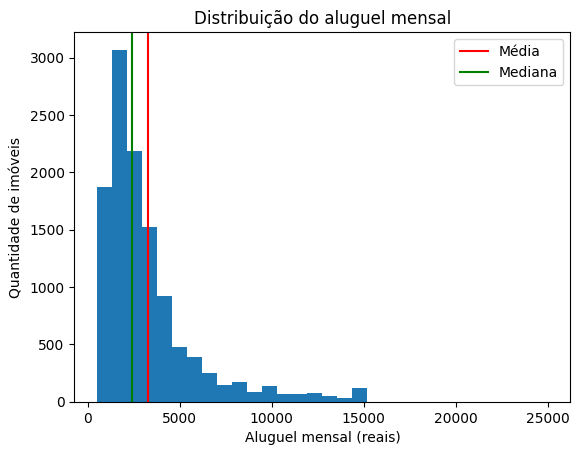

In [40]:
import os
import matplotlib.pyplot as plt

os.makedirs("images", exist_ok=True)

plt.hist(df_limpo["rent"], bins=30)
plt.axvline(df_limpo["rent"].mean(), color="red", label="Média")
plt.axvline(df_limpo["rent"].median(), color="green", label="Mediana")
plt.title("Distribuição do aluguel mensal")
plt.xlabel("Aluguel mensal (reais)")
plt.ylabel("Quantidade de imóveis")
plt.legend()
plt.savefig("images/grafico_1_histograma_aluguel.png", dpi=150, bbox_inches="tight")
plt.show()

O histograma mostra como os aluguéis se distribuem. A maioria dos imóveis tem aluguel
mais baixo, e poucos têm aluguéis muito altos, o que forma uma cauda comprida à direita:
todos os outros imóveis ficam até R\$ 15.000, e apenas um passa disso (R\$ 25.000). A
linha vermelha marca a média (R\$ 3.250,96) e a verde marca a mediana (R\$ 2.415): como
os aluguéis mais altos puxam a média para cima, ela fica à direita da mediana.

In [41]:
(df_limpo["rent"] == 15000).sum()

np.int64(113)

In [42]:
(df_limpo["rent"] > 15000).sum()

np.int64(1)

Cerca de 113 anúncios (1%) têm aluguel de exatamente R\$ 15.000, o que forma um pico no
histograma, e só um imóvel passa disso. Os dados não permitem saber o motivo (por
exemplo, um limite de preço no anúncio ou arredondamento), então os aluguéis mais altos
devem ser lidos com cuidado.

## Bairros com aluguel médio mais alto

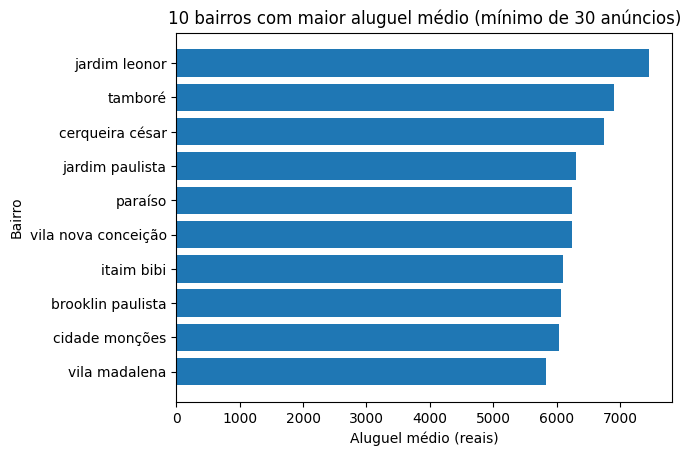

In [43]:
top = bairros_30.sort_values("mean", ascending=False).head(10)

plt.barh(top.index, top["mean"])
plt.gca().invert_yaxis()
plt.title("10 bairros com maior aluguel médio (mínimo de 30 anúncios)")
plt.xlabel("Aluguel médio (reais)")
plt.ylabel("Bairro")
plt.savefig("images/grafico_2_bairros_mais_caros.png", dpi=150, bbox_inches="tight")
plt.show()

O gráfico mostra os 10 bairros com maior aluguel médio, entre os que têm pelo menos 30
anúncios. O mais caro é Jardim Leonor (média de R\$ 7.456) e o décimo é Vila Madalena
(R\$ 5.835). Em vários deles a média fica bem acima da mediana (por exemplo, Vila
Madalena: R\$ 5.835 contra R\$ 4.125), o que indica que alguns aluguéis muito altos
elevam a média. Tamboré também aparece no ranking.

## Área e aluguel

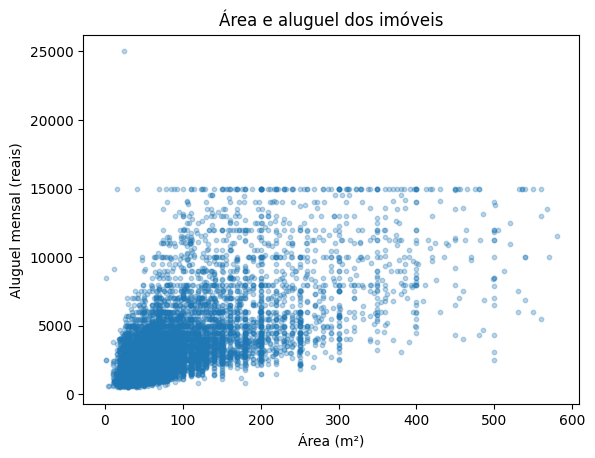

In [44]:
plt.scatter(df_limpo["area"], df_limpo["rent"], alpha=0.3, s=10)
plt.title("Área e aluguel dos imóveis")
plt.xlabel("Área (m²)")
plt.ylabel("Aluguel mensal (reais)")
plt.savefig("images/grafico_3_area_aluguel.png", dpi=150, bbox_inches="tight")
plt.show()

Cada ponto é um imóvel. O gráfico mostra que, em geral, quanto maior a área, maior o
aluguel, o que combina com a correlação de 0,67 calculada antes. A relação, porém, não
é perfeita: imóveis com a mesma área têm aluguéis bem diferentes, então a área sozinha
não explica o preço (a localização, por exemplo, também pesa). A maioria dos imóveis é
pequena (a mediana da área é de uns 60 m²), por isso os pontos ficam concentrados à
esquerda. A linha de pontos em R\$ 15.000 corresponde aos 113 anúncios com esse valor
exato, e há um imóvel isolado em R\$ 25.000.

In [45]:
df_limpo[df_limpo["rent"] > 15000]

,address,district,area,bedrooms,garage,type,rent,total,district_norm,diferenca
6095,Avenida Chibarás,Planalto Paulista,24,1,0,Studio e kitnet,25000,26710,planalto paulista,1710


Há um imóvel com aluguel de R\$ 25.000 que destoa do restante: é um studio e kitnet de
24 m², sem vaga, em um tipo cuja mediana é R\$ 1.850. Não consigo saber se é um erro de
digitação ou um valor real, então mantive o imóvel na análise. Ele muda a média geral em
apenas cerca de R\$ 2, então o efeito é muito pequeno.

## Conclusões e limitações

### O que acompanha os maiores e os menores aluguéis

Os aluguéis mais altos acompanham imóveis maiores, com mais quartos e mais vagas, e
bairros como Jardim Leonor, Tamboré e Cerqueira César. A área tem correlação de 0,67
com o aluguel, as vagas 0,62 e os quartos 0,53. A mediana do aluguel vai de R\$ 1.711
(1 quarto) a R\$ 8.000 (5 quartos).

Os aluguéis mais baixos aparecem em studios e kitnets (mediana de R\$ 1.850) e em
bairros como Taboão, Sé e Campos Elíseos, que têm os menores aluguéis médios entre os
bairros com pelo menos 30 anúncios.

Os dados não permitem concluir que uma característica cause o aluguel, porque
correlação mostra só que as coisas andam juntas, e área, quartos e vagas se
relacionam entre si (correlações entre 0,66 e 0,73). Também não permitem saber o preço
negociado, o estado do imóvel ou o efeito isolado de cada característica.

### Conclusões

1. A mediana do aluguel é R\$ 2.415 e a média é R\$ 3.250,96. A média fica acima porque
   poucos aluguéis muito altos a puxam para cima.
2. Studio e kitnet é o tipo mais barato (mediana de R\$ 1.850), contra R\$ 2.500 do
   apartamento e R\$ 2.600 da casa.
3. O aluguel acompanha a área (correlação de 0,67) e os quartos: a mediana sobe de
   R\$ 1.711 com 1 quarto para R\$ 8.000 com 5 quartos, cerca de 4,7 vezes.
4. Entre os bairros com pelo menos 30 anúncios, o mais caro é Jardim Leonor (média de
   R\$ 7.456) e o mais barato é Taboão (R\$ 1.473), uma diferença de cerca de 5 vezes.
5. Os anúncios são muito concentrados: apartamentos são 62% do total, e os 78 bairros
   com pelo menos 30 anúncios, de 1.178, cobrem só cerca de 50% dos imóveis.

### Limitações

- Os valores são de anúncios, e o preço anunciado pode ser diferente do preço negociado.
- Os anúncios são concentrados: 62% são apartamentos, e só 78 dos 1.178 bairros têm
  pelo menos 30 anúncios. O ranking de bairros cobre cerca de metade dos imóveis.
- O ranking muda conforme o corte de anúncios escolhido (10, 30 ou 50). Só Cerqueira
  César aparece entre os 10 mais caros nos três cortes.
- Não verifiquei se bairros como Alphaville, Tamboré e Taboão ficam na cidade de São
  Paulo, então o dataset pode incluir imóveis de fora da capital.
- Cerca de 113 anúncios (1%) têm aluguel de exatamente R\$ 15.000, o que forma um pico no
  histograma, e só um imóvel passa disso (R\$ 25.000, um studio de 24 m² que destoa do
  tipo). Os dados não permitem saber o motivo, e mantive esses imóveis na análise.
- 37 imóveis têm 0 quartos. Isso é esperado em studios, mas 4 casas nessa situação
  (uma delas com 250 m²) sugerem que o número de quartos pode não ter sido preenchido.
- O dataset não informa quando os anúncios foram coletados, e não tem banheiros, idade
  do imóvel nem estado de conservação.
- Correlação não prova causa, e como área, quartos e vagas se relacionam entre si, não
  dá para separar o efeito de cada uma.

### Uso de inteligência artificial

Usei o Claude para aprender comandos do pandas e organizar a análise. Executei e conferi
todos os resultados no Colab, e as decisões e conclusões são minhas. Detalhes completos
no README.